# 01 — Data Understanding

## TopicSense NLP: Supervised Multi-Class Text Classification

### CRISP-DM Phase 2

**Dataset:** 20 Newsgroups
**Task:** Supervised multi-class text classification
**Number of documents:** 18,846
**Number of classes:** 20
**Primary evaluation metric:** Macro F1-score

---

## 1. Introduction

The purpose of this notebook is to conduct a systematic examination of the 20 Newsgroup datset before preprocessing and model development.

The project investigates supervised classification of textual documents into predefined topic categories.

Data understanding will establish the dataset's structure, quality, class distribution, document characteristics and potential sources of information leakage.

The analysis will inform subsequent data preparation decisions while preserving the original acquired data.

### Research objectives

1. Establish the structural characteristics of the dataset.
2. Assess data completeness and integrity.
3. Examine topic-class distribution and imbalance.
4. Analyse document length and textual characteristics.
5. Investigate potential duplicates and train-test overlap.
6. Identify metadata and other potential sources of information leakage.
7. Establish evidence-based requirements for data preparation.

## 2. Analytical Approach

The analysis uses descriptive statistics, data-quality checks and
visual exploration.

The original training and test partitions are retained as supplied
by the dataset.

No text cleaning, token removal, stemming, lemmatization or feature
engineering is performed in this notebook.

The analysis is exploratory: its purpose is to understand the data
and justify subsequent preparation decisions, not to optimise
classification performance.

The training and test partitions may be described independently,
but the test partition will not be used to select models,
hyperparameters or preprocessing configurations.

In [65]:

from pathlib import Path
import json
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import adjusted_mutual_info_score

RANDOM_SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start_path: Path) -> Path:
    """Find the project root by locating pyproject.toml."""
    for directory in (start_path, *start_path.parents):
        if (directory / "pyproject.toml").is_file():
            return directory

    raise FileNotFoundError(
        "Could not locate the TopicSense project root. "
        "Ensure the notebook is stored inside the repository."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "20newsgroups"

TRAIN_PATH = DATA_DIR / "train.jsonl"
TEST_PATH = DATA_DIR / "test.jsonl"
METADATA_PATH = DATA_DIR / "metadata.json"

for path in (TRAIN_PATH, TEST_PATH, METADATA_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset file not found: {path}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset directory: {DATA_DIR}")
print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Dataset directory: /home/nkululekocyrilcele/projects/topicsense-nlp/data/raw/20newsgroups
Python version: 3.12.3
NumPy version: 2.5.5
Pandas version: 3.1.1


## 3. Dataset Acquisition and Provenance

The 20 Newsgroups dataset was acquired using scikit-learn's
`fetch_20newsgroups` loader.

The original text was preserved during acquisition. In particular,
headers, footers and quoted messages were not removed.

The dataset was saved in JSON Lines format, with one document
per record.

The original train-test partition was preserved.

In [3]:
with TRAIN_PATH.open("r", encoding="utf-8") as file:
    train_data = pd.read_json(file, lines=True)

with TEST_PATH.open("r", encoding="utf-8") as file:
    test_data = pd.read_json(file, lines=True)

with METADATA_PATH.open("r", encoding="utf-8") as file:
    dataset_metadata = json.load(file)

print("training partition:")
display(train_data.head(3))

print("\nTest partition:")
display(train_data.head(3))

print("\nTest partition:")
display(test_data.head(3))

print("\nDataset metadata:")
display(pd.Series(dataset_metadata, dtype="object"))

training partition:


,document_id,text,label,label_name,split
0,train_000000,From: cubbie@garnet.berkeley.edu ( )\nSubject: Re: Cubs behind Marlins? How?\nArticle-...,9,rec.sport.baseball,train
1,train_000001,From: gnelson@pion.rutgers.edu (Gregory Nelson)\nSubject: Thanks Apple: Free Ethernet on my C610!\nArticle-I.D.: pio...,4,comp.sys.mac.hardware,train
2,train_000002,From: crypt-comments@math.ncsu.edu\nSubject: Cryptography FAQ 10/10 - References\nOrganization: The Crypt Cabal\nLin...,11,sci.crypt,train



Test partition:


,document_id,text,label,label_name,split
0,train_000000,From: cubbie@garnet.berkeley.edu ( )\nSubject: Re: Cubs behind Marlins? How?\nArticle-...,9,rec.sport.baseball,train
1,train_000001,From: gnelson@pion.rutgers.edu (Gregory Nelson)\nSubject: Thanks Apple: Free Ethernet on my C610!\nArticle-I.D.: pio...,4,comp.sys.mac.hardware,train
2,train_000002,From: crypt-comments@math.ncsu.edu\nSubject: Cryptography FAQ 10/10 - References\nOrganization: The Crypt Cabal\nLin...,11,sci.crypt,train



Test partition:


,document_id,text,label,label_name,split
0,test_000000,From: stimpy@dev-null.phys.psu.edu (Gregory Nagy)\nSubject: Re: ESPN UP YOURS .........\nOrganization: Penn State La...,10,rec.sport.hockey,test
1,test_000001,From: kennejs@a.cs.okstate.edu (KENNEDY JAMES SCOT)\nSubject: Re: Blast them next time\nOrganization: Oklahoma State...,16,talk.politics.guns,test
2,test_000002,From: perky@acs.bu.edu (Melissa Sherrin)\nSubject: Re: moon image in weather sat image\nOrganization: Boston Univers...,14,sci.space,test



Dataset metadata:


dataset                                                                                                                                       20 Newsgroups
source                                                                                                                      scikit-learn fetch_20newsgroups
source_url                                                          https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset
task_type                                                                                                                    multiclass_text_classification
number_of_classes                                                                                                                                        20
classes                             [alt.atheism, comp.graphics, comp.os.ms-windows.misc, comp.sys.ibm.pc.hardware, comp.sys.mac.hardware, comp.windows....
split_counts                                                    

In [5]:
datasets = {
    "Training": train_data,
    "Test": test_data,
}

overview = pd.DataFrame(
    {
        name: {
            "Documents": len(data),
            "Columns": len(data.columns),
            "Missing values": int(data.isna().sum().sum()),
            "Unique document IDs": data["document_id"].nunique(),
            "Unique classes": data["label"].nunique(),
        }
        for name, data in datasets.items()
    }
).T

display(overview)

,Documents,Columns,Missing values,Unique document IDs,Unique classes
Training,11314,5,0,11314,20
Test,7532,5,0,7532,20


## 4.1 Structural Validation

This section examines the schema, data types, missing values and
consistency of the dataset records.

The expected schema is:

- `document_id`: unique identifier for each document.
- `text`: original document content.
- `label`: integer-encoded target class.
- `label_name`: human-readable target class.
- `split`: official dataset partition.

These checks establish whether the acquired data conforms to the
expected structure before further analysis.

In [7]:
EXPECTED_COLUMNS = [
    "document_id",
    "text",
    "label",
    "label_name",
    "split",
]

for split_name, data in datasets.items():
    print(f"\n{split_name} partition")
    print("=" * 60)

    print("\nData types:")
    display(data.dtypes.rename("Data type").to_frame())

    print("\nData types:")
    display(data.dtypes.rename("Data type").to_frame())

    print("\nMissing values by column:")
    missing_summary = pd.DataFrame({
        "Missing values": data.isna().sum(),
        "Missing percentage": (
            data.isna().mean() * 100
        ).round(3),
    })
    display(missing_summary)

    print("\nUnexpected columns:")
    print(sorted(set(data.columns) - set(EXPECTED_COLUMNS)))

    print("\nMissing expected columns:")
    print(sorted(set(EXPECTED_COLUMNS) - set(data.columns)))


Training partition

Data types:


,Data type
document_id,str
text,str
label,int64
label_name,str
split,str



Data types:


,Data type
document_id,str
text,str
label,int64
label_name,str
split,str



Missing values by column:


,Missing values,Missing percentage
document_id,0,0.0
text,0,0.0
label,0,0.0
label_name,0,0.0
split,0,0.0


... (3 outputs left out)

,Data type
document_id,str
text,str
label,int64
label_name,str
split,str



Missing values by column:


,Missing values,Missing percentage
document_id,0,0.0
text,0,0.0
label,0,0.0
label_name,0,0.0
split,0,0.0



Unexpected columns:
[]

Missing expected columns:
[]


In [15]:

integrity_results = []

expected_splits = {
    "Training": "train",
    "Test": "test",
}

for split_name, data in datasets.items():
    expected_split = expected_splits[split_name]

    results = {
        "Partition": split_name,
        "Rows": len(data),
        "Duplicate document IDs": int(
            data["document_id"].duplicated().sum()
        ),
        "Empty document IDs": int(
            data["document_id"].isna().sum()
        ),
        "Empty text documents": int(
            data["text"].str.strip().eq("").sum()
        ),
        "Invalid label values": int(
            (~data["label"].between(0, 19)).sum()
        ),
        "Unexpected split values": int(
            (~data["split"].eq(expected_split)).sum()
        ),
        "Label-name inconsistencies": int(
            (
                data["label_name"]
                != data["label"].map(
                    dict(enumerate(dataset_metadata["classes"]))
                )
            ).sum()
        ),
    }

    integrity_results.append(results)

integrity_summary = pd.DataFrame(integrity_results).set_index(
    "Partition"
)

display(integrity_summary)

,Rows,Duplicate document IDs,Empty document IDs,Empty text documents,Invalid label values,Unexpected split values,Label-name inconsistencies
Partition,,,,,,,
Training,11314,0,0,0,0,0,0
Test,7532,0,0,0,0,0,0


In [11]:
expected_counts = {
    "train": 11314,
    "test": 7532,
}

actual_counts = {
    "train": len(train_data),
    "test": len(test_data),
}

count_comparison = pd.DataFrame({
    "Expected documents": expected_counts,
    "Actual documents": actual_counts,
})

count_comparison["Difference"] = (
    count_comparison["Actual documents"]
    - count_comparison["Expected documents"]
)

display(count_comparison)

print(f"\nTotal documents: {sum(actual_counts.values()):,}")
print(f"Toatal classes: {len(dataset_metadata['classes'])}")

,Expected documents,Actual documents,Difference
train,11314,11314,0
test,7532,7532,0



Total documents: 18,846
Toatal classes: 20


## 5. Duplicate-Document Analysis

Duplicate detection is important because repeated documents can
inflate evaluation results if identical content appears in both
training and test partitions.

This analysis distinguishes:

1. Duplicate documents within the training partition.
2. Duplicate documents within the test partition.
3. Exact document overlap between training and test partitions.

The analysis uses the original document text. No normalization or
text cleaning is applied before comparison.

This detects exact duplicates, not semantically similar documents
or near-duplicates.

In [13]:
train_texts = train_data["text"].fillna("")
test_texts = test_data["text"].fillna("")

train_duplicate_count = int(train_texts.duplicated().sum())
test_duplicate_count = int(test_texts.duplicated().sum())

train_unique_texts = set(train_texts)
test_unique_texts = set(test_texts)

cross_split_overlap = train_unique_texts.intersection(
    test_unique_texts
)

duplicate_summary = pd.DataFrame(
    {
        "Measure": [
            "Duplicate documents in training",
            "Duplicate documents in test",
            "Unique training documents",
            "Unique test documents",
            "Exact texts shared across partitions",
        ],
        "Count": [
            train_duplicate_count,
            test_duplicate_count,
            len(train_unique_texts),
            len(test_unique_texts),
            len(cross_split_overlap),
        ],
    }
)

display(duplicate_summary)

,Measure,Count
0,Duplicate documents in training,0
1,Duplicate documents in test,0
2,Unique training documents,11314
3,Unique test documents,7532
4,Exact texts shared across partitions,0


In [14]:
if cross_split_overlap:
    overlapping_documents = pd.DataFrame({
        "text": list(cross_split_overlap)
    })

    print("Exact documents shared across partitions:")
    display(overlapping_documents.head())
else:
    print("No exact document-text overlap found between partitions.")

No exact document-text overlap found between partitions.


## 5. Class Distribution and Imbalance

The dataset contains 20 predefined newsgroup categories.

Class distribution is examined separately for the training and
test partitions to understand representation across categories.

The analysis includes:

- Document counts per class.
- Relative class frequencies.
- Class imbalance ratios.
- Differences between training and test distributions.

Class imbalance is relevant because classification models can
favour frequently represented categories.

Macro-averaged F1-score is retained as the primary evaluation
metric because it assigns equal importance to each class.

In [18]:
class_names = dataset_metadata["classes"]

train_counts = (
    train_data["label_name"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

test_counts = (
    test_data["label_name"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

class_distribution = pd.DataFrame({
    "Training": train_counts,
    "Test": test_counts,
})

class_distribution["Training (%)"] = (
    class_distribution["Training"]
    / len(train_data) * 100
)

class_distribution["Test (%)"] = (
    class_distribution["Test"]
    / len(test_data) * 100
)

display(
    class_distribution.round(2).sort_values(
        "Training",
        ascending=False,
    )
)

,Training,Test,Training (%),Test (%)
label_name,,,,
rec.sport.hockey,600,399,5.30,5.30
soc.religion.christian,599,398,5.29,5.28
rec.motorcycles,598,398,5.29,5.28
rec.sport.baseball,597,397,5.28,5.27
sci.crypt,595,396,5.26,5.26
rec.autos,594,396,5.25,5.26
sci.med,594,396,5.25,5.26
comp.windows.x,593,395,5.24,5.24
sci.space,593,394,5.24,5.23


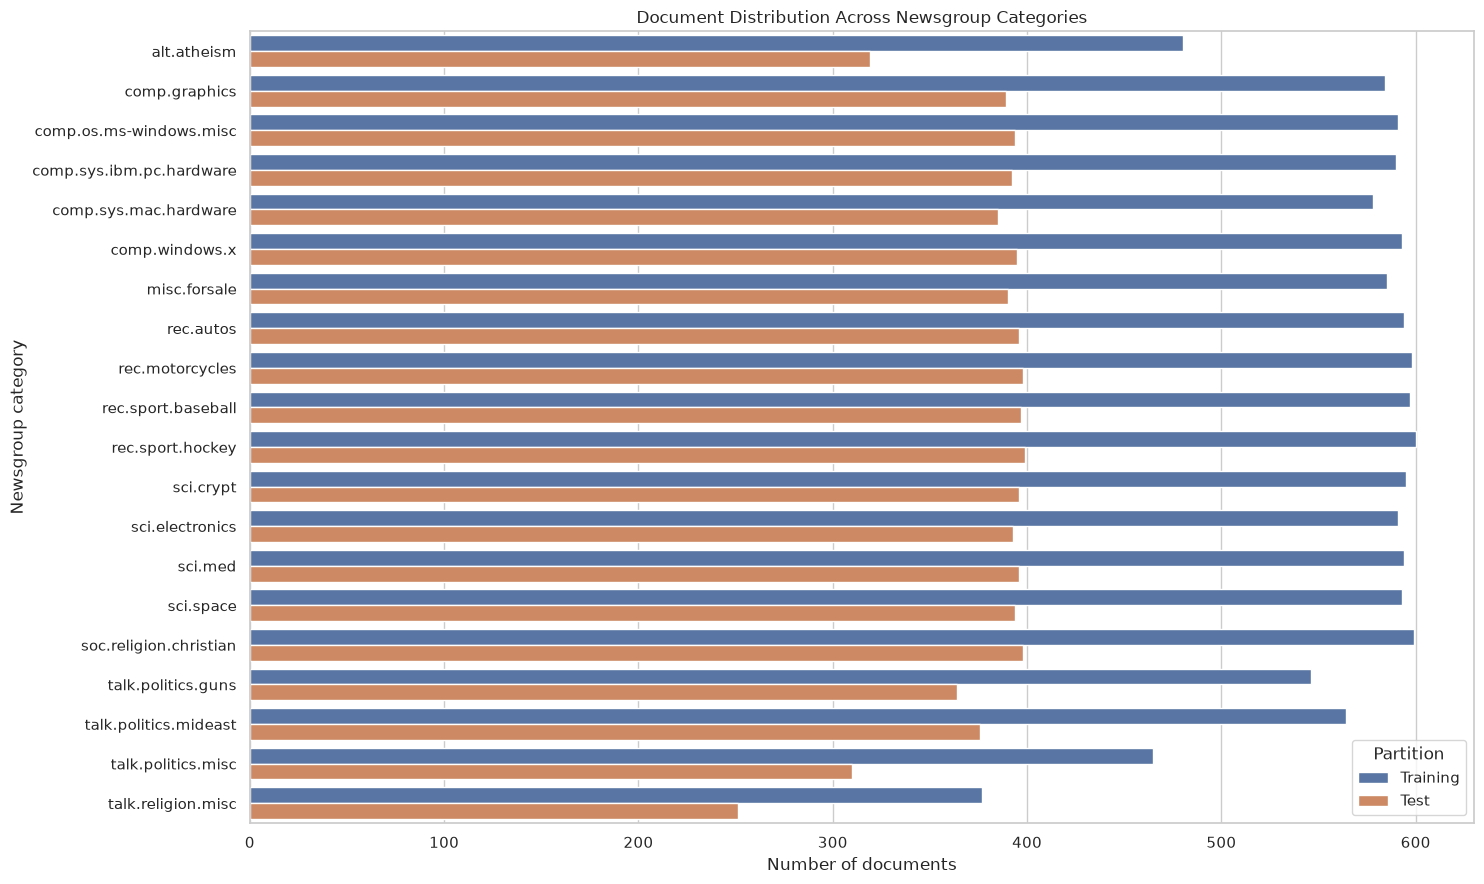

In [19]:
class_plot_data = (
    class_distribution[["Training", "Test"]]
    .reset_index(names="Class")
    .melt(
        id_vars="Class",
        var_name="Partition",
        value_name="Documents",
    )
)

plt.figure(figsize=(15, 9))

sns.barplot(
    data=class_plot_data,
    x="Documents",
    y="Class",
    hue="Partition",
)

plt.title("Document Distribution Across Newsgroup Categories")
plt.xlabel("Number of documents")
plt.ylabel("Newsgroup category")
plt.legend(title="Partition")
plt.tight_layout()
plt.show()

In [20]:
imbalance_summary = pd.DataFrame({
    "Partition": ["Training", "Test"],
    "Minimum class count": [
        train_counts.min(),
        test_counts.min(),
    ],
    "Maximum class count": [
        train_counts.max(),
        test_counts.max(),
    ],
    "Mean class count": [
        train_counts.mean(),
        test_counts.mean(),
    ],
    "Class imbalance ratio": [
        train_counts.max() / train_counts.min(),
        test_counts.max() / test_counts.min(),
    ],
})

display(imbalance_summary.round(3))

,Partition,Minimum class count,Maximum class count,Mean class count,Class imbalance ratio
0,Training,377,600,565.7,1.592
1,Test,251,399,376.6,1.590


In [21]:
distribution_comparison = pd.DataFrame({
    "Training (%)": (
        train_counts / len(train_data) * 100
    ),
    "Test (%)": (
        test_counts / len(test_data) * 100
    ),
})

distribution_comparison["Absolute Difference (pp)"] = (
    distribution_comparison["Training (%)"]
    - distribution_comparison["Test (%)"]
).abs()

display(
    distribution_comparison.sort_values(
        "Absolute Difference (pp)",
        ascending=False,
    ).round(3)
)

,Training (%),Test (%),Absolute Difference (pp)
label_name,,,
comp.sys.ibm.pc.hardware,5.215,5.204,0.010
sci.space,5.241,5.231,0.010
soc.religion.christian,5.294,5.284,0.010
rec.autos,5.250,5.258,0.007
sci.med,5.250,5.258,0.007
comp.os.ms-windows.misc,5.224,5.231,0.007
misc.forsale,5.171,5.178,0.007
alt.atheism,4.243,4.235,0.007
talk.politics.mideast,4.985,4.992,0.007


### Class Distribution Findings

The dataset contains all 20 target categories in both partitions.

The training partition has between 377 and 600 documents per class,
while the test partition has between 251 and 399 documents per class.

The class imbalance ratios are approximately 1.592 for training
and 1.590 for testing. This indicates relatively modest class
imbalance rather than severe underrepresentation.

The training and test class proportions are also highly consistent.
The largest absolute difference between corresponding class
proportions is approximately 0.01 percentage points.

These findings support retaining the original class distributions
without applying oversampling, undersampling or synthetic
minority-class generation at this stage.

Macro-F1 remains the primary evaluation metric because it gives
each of the 20 categories equal weight, regardless of its frequency.

The official test partition will remain unchanged.

## 6. Document Length and Textual Characteristics

Document length is an important characteristic of text datasets.

Very short documents may contain insufficient contextual information
for reliable topic classification. Extremely long documents may
increase computational costs and require truncation when processed
by transformer models.

Two length measurements are used:

1. Character count: the number of characters in each original document.
2. Word count: the number of whitespace-separated tokens.

Whitespace-separated word counts are used as a simple descriptive
measure. They are not equivalent to linguistic tokenization or
transformer subword tokenization.

The analysis compares training and test distributions without
modifying the original document text.

In [22]:
for data in datasets.values():
    data["character_count"] = data["text"].str.len()

    data["word_count"] = data["text"].str.split().str.len()

length_summary = pd.DataFrame({
    split_name: {
        "Mean characters": data["character_count"].mean(),
        "Median characters": data["character_count"].median(),
        "Minimum characters": data["character_count"].min(),
        "Maximum characters": data["character_count"].max(),
        "Mean words": data["word_count"].mean(),
        "Median words": data["word_count"].median(),
        "Minimum words": data["word_count"].min(),
        "Maximum words": data["word_count"].max(),
    }
    for split_name, data in datasets.items()
}).T

display(length_summary.round(2))

,Mean characters,Median characters,Minimum characters,Maximum characters,Mean words,Median words,Minimum words,Maximum words
Training,1949.31,1178.0,125.0,75154.0,287.47,176.0,14.0,11821.0
Test,1832.25,1168.5,115.0,160616.0,277.93,173.0,12.0,9578.0


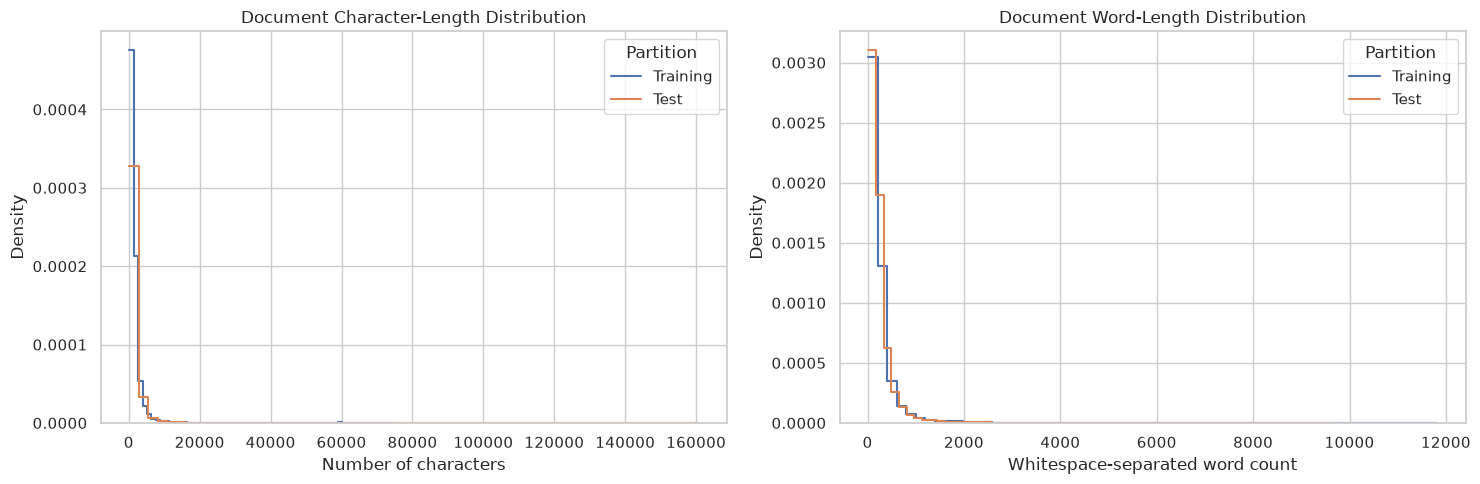

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for split_name, data in datasets.items():
    sns.histplot(
        data=data,
        x="character_count",
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=split_name,
        ax=axes[0],
    )

    sns.histplot(
        data=data,
        x="word_count",
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=split_name,
        ax=axes[1],
    )

axes[0].set_title("Document Character-Length Distribution")
axes[0].set_xlabel("Number of characters")
axes[0].set_ylabel("Density")
axes[0].legend(title="Partition")

axes[1].set_title("Document Word-Length Distribution")
axes[1].set_xlabel("Whitespace-separated word count")
axes[1].set_ylabel("Density")
axes[1].legend(title="Partition")

plt.tight_layout()
plt.show()

In [24]:
percentiles = [0.00, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]

percentile_results = []

for split_name, data in datasets.items():
    for measure in ("character_count", "word_count"):
        values = data[measure].quantile(percentiles)

        for percentile, value in values.items():
            percentile_results.append({
                "Partition": split_name,
                "Measure": measure,
                "Percentile": f"{percentile:.0%}",
                "Length": value,
            })

percentile_table = pd.DataFrame(percentile_results)

display(
    percentile_table.pivot_table(
        index=["Measure", "Percentile"],
        columns="Partition",
        values="Length",
    ).round(2)
)

Partition                        Test  Training
Measure         Percentile                     
character_count 0%             115.00    125.00
                10%            490.00    499.00
                100%        160616.00  75154.00
                25%            748.00    753.25
                50%           1168.50   1178.00
                75%           1861.00   1881.00
                90%           3147.00   3161.00
                95%           4502.15   4844.05
                99%          12463.83  14328.01
word_count      0%              12.00     14.00
                10%             69.00     69.00
                100%          9578.00  11821.00
                25%            107.00    108.00
                50%            173.00    176.00
                75%            292.00    293.00
                90%            501.00    508.00
                95%            732.00    772.00
                99%           1942.38   1956.00

In [25]:
for split_name, data in datasets.items():
    print(f"\n{split_name}: Shortest documents")
    display(
        data.nsmallest(5, "word_count")[
            ["document_id", "label_name", "character_count", "word_count"]
        ]
    )

    print(f"\n{split_name}: Longest documents")
    display(
        data.nlargest(5, "word_count")[
            ["document_id", "label_name", "character_count", "word_count"]
        ]
    )


Training: Shortest documents


,document_id,label_name,character_count,word_count
182,train_000182,comp.sys.mac.hardware,125,14
7299,train_007299,comp.windows.x,169,15
10389,train_010389,rec.autos,131,15
3871,train_003871,comp.graphics,245,16
4577,train_004577,comp.windows.x,163,16



Training: Longest documents


,document_id,label_name,character_count,word_count
7137,train_007137,sci.electronics,72637,11821
7833,train_007833,rec.sport.hockey,75154,11278
3412,train_003412,talk.politics.mideast,62187,11263
348,train_000348,talk.politics.mideast,56402,10365
1176,train_001176,comp.windows.x,66459,9523



Test: Shortest documents


,document_id,label_name,character_count,word_count
6627,test_006627,alt.atheism,115,12
1001,test_001001,comp.windows.x,145,14
5872,test_005872,comp.windows.x,129,14
7314,test_007314,comp.windows.x,147,14
5696,test_005696,comp.windows.x,287,15



Test: Longest documents


,document_id,label_name,character_count,word_count
3761,test_003761,talk.politics.mideast,53119,9578
5377,test_005377,comp.graphics,57725,9255
6519,test_006519,comp.graphics,57481,9225
5581,test_005581,sci.space,57022,9138
1493,test_001493,comp.windows.x,56625,8586


In [26]:
class_length_summary = (
    train_data.groupby("label_name")
    .agg(
        document_count=("document_id", "count"),
        mean_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        min_words=("word_count", "min"),
        max_words=("word_count", "max"),
    )
    .sort_values("median_words", ascending=False)
)

display(class_length_summary.round(2))

,document_count,mean_words,median_words,min_words,max_words
label_name,,,,,
talk.politics.mideast,564,499.72,269.0,19,11263
soc.religion.christian,599,372.40,262.0,23,2976
talk.politics.misc,465,447.00,251.0,19,7989
talk.politics.guns,546,368.51,250.5,33,8452
sci.crypt,595,382.03,214.0,34,8943
alt.atheism,480,345.24,210.0,33,8648
talk.religion.misc,377,356.26,208.0,26,4767
rec.sport.hockey,600,305.41,184.5,17,11278
sci.space,593,300.03,181.0,20,6141


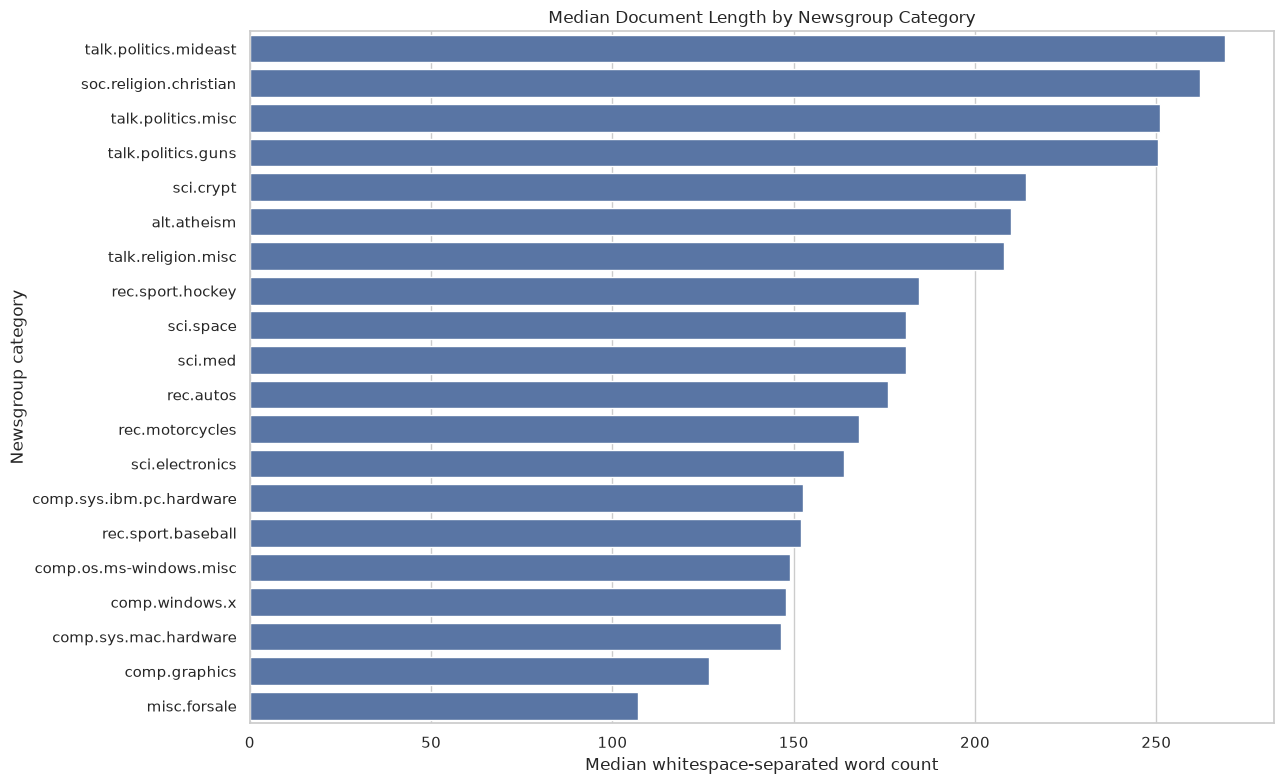

In [27]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=class_length_summary.reset_index(),
    x="median_words",
    y="label_name",
)

plt.title("Median Document Length by Newsgroup Category")
plt.xlabel("Median whitespace-separated word count")
plt.ylabel("Newsgroup category")
plt.tight_layout()
plt.show()

## 6.1 Investigation of Extreme Document Lengths

The descriptive analysis identified unusually long documents,
including a test document containing 160,616 characters.

Extreme document lengths can arise from legitimate long discussions,
quoted correspondence, embedded data, formatting artefacts or
unusually large messages.

These records should not automatically be treated as invalid.

This investigation examines the longest documents by character
count and compares their character counts, whitespace-separated
word counts and line counts.

The objective is to distinguish legitimate long documents from
potential formatting anomalies before determining how they should
be handled during data preparation.

In [28]:
for split_name, data in datasets.items():
    print(f"\n{split_name}: Ten longest documents by character count")

    display(
        data.nlargest(10, "character_count")[
            [
                "document_id",
                "label_name",
                "character_count",
                "word_count",
            ]
        ]
    )


Training: Ten longest documents by character count


,document_id,label_name,character_count,word_count
7833,train_007833,rec.sport.hockey,75154,11278
7137,train_007137,sci.electronics,72637,11821
2149,train_002149,talk.politics.guns,71400,8452
1176,train_001176,comp.windows.x,66459,9523
3327,train_003327,comp.os.ms-windows.misc,63095,2335
3412,train_003412,talk.politics.mideast,62187,11263
10047,train_010047,sci.crypt,61489,8520
8630,train_008630,comp.graphics,60713,7939
10227,train_010227,comp.os.ms-windows.misc,60227,1169
5662,train_005662,comp.os.ms-windows.misc,59304,987



Test: Ten longest documents by character count


,document_id,label_name,character_count,word_count
6306,test_006306,comp.os.ms-windows.misc,160616,5464
6890,test_006890,comp.graphics,61773,8059
3106,test_003106,comp.graphics,58566,8232
5377,test_005377,comp.graphics,57725,9255
6636,test_006636,comp.windows.x,57687,6062
6519,test_006519,comp.graphics,57481,9225
5581,test_005581,sci.space,57022,9138
1493,test_001493,comp.windows.x,56625,8586
3761,test_003761,talk.politics.mideast,53119,9578
5026,test_005026,comp.sys.mac.hardware,52357,7847


In [29]:
longest_test_document = test_data.loc[
    test_data["character_count"].idxmax()
]

longest_text = longest_test_document["text"]

print("Document ID:", longest_test_document["document_id"])
print("Topic:", longest_test_document["label_name"])
print("Characters:", len(longest_text))
print("Whitespace-separated words:", len(longest_text.split()))
print("Lines:", len(longest_text.splitlines()))
print("Average characters per whitespace-separated word:",
      round(len(longest_text) / max(len(longest_text.split()), 1), 2))

print("\nFirst 1,500 characters:")
print(longest_text[:1500])

print("\nLast 1,500 characters:")
print(longest_text[-1500:])

Document ID: test_006306
Topic: comp.os.ms-windows.misc
Characters: 160616
Whitespace-separated words: 5464
Lines: 2609
Average characters per whitespace-separated word: 29.4

First 1,500 characters:
From: dbushong@wang.com (Dave Bushong)
Subject: Re: More Cool BMP files??
Organization: Wang Labs, Lowell MA, USA
Distribution: usa
Lines: 2603

adair@atldbs.dbsoftware.com (Owen Adair) writes:

>In article <1993Apr20.173506.2288@dlss2> james@dlss2 (James Cummings) writes:
>>Newsgroups: comp.os.ms-windows.misc
>>Path: atldbs!uupsi!psinntp!uunet!gatech!howland.reston.ans.net!bogus.sura.net!darwin.sura.net!convex!seas.smu.edu!void!dalnet!dlss2!james
>>From: james@dlss2 (James Cummings)
>>Subject: Re: More Cool BMP files??
>>Message-ID: <1993Apr20.173506.2288@dlss2>
>>Organization: RedRock Development
>>References: <1993Apr17.023017.17301@gmuvax2.gmu.edu>
>>Distribution: usa
>>Date: Tue, 20 Apr 1993 17:35:06 GMT
>>Lines: 1021
>>In article <1993Apr17.023017.17301@gmuvax2.gmu.edu> rwang@gmuvax2

In [30]:
formatting_results = []

for split_name, data in datasets.items():
    for _, document in data.nlargest(5, "character_count").iterrows():
        text = document["text"]

        formatting_results.append({
            "Partition": split_name,
            "Document ID": document["document_id"],
            "Topic": document["label_name"],
            "Characters": len(text),
            "Words": len(text.split()),
            "Lines": len(text.splitlines()),
            "Blank lines": sum(
                not line.strip() for line in text.splitlines()
            ),
            "Tabs": text.count("\t"),
            "Non-ASCII characters": sum(
                ord(character) > 127 for character in text
            ),
            "Control characters": sum(
                ord(character) < 32
                and character not in "\n\r\t"
                for character in text
            ),
        })

formatting_summary = pd.DataFrame(formatting_results)

display(formatting_summary)

,Partition,Document ID,Topic,Characters,Words,Lines,Blank lines,Tabs,Non-ASCII characters,Control characters
0,Training,train_007833,rec.sport.hockey,75154,11278,1776,339,0,0,0
1,Training,train_007137,sci.electronics,72637,11821,1555,261,1389,0,0
2,Training,train_002149,talk.politics.guns,71400,8452,1844,423,34,0,0
3,Training,train_001176,comp.windows.x,66459,9523,1619,275,832,0,0
4,Training,train_003327,comp.os.ms-windows.misc,63095,2335,1027,4,1,0,0
5,Test,test_006306,comp.os.ms-windows.misc,160616,5464,2609,6,1,0,0
6,Test,test_006890,comp.graphics,61773,8059,1596,361,243,0,0
7,Test,test_003106,comp.graphics,58566,8232,1531,311,37,0,0
8,Test,test_005377,comp.graphics,57725,9255,1052,186,82,0,0
9,Test,test_006636,comp.windows.x,57687,6062,1841,160,1,0,0


## 7. Investigation of Headers, Quoted Messages and Metadata

The 20 Newsgroups dataset consists of archived discussion messages.
Consequently, its documents may contain more than the main message body.

Potential components include:

- Email headers, such as From, Subject, Organization and Newsgroups.
- Quoted messages from earlier discussions.
- Email signatures and footer information.
- Encoded attachments and non-prose content.
- Message-routing and distribution metadata.

These components may introduce irrelevant information or target leakage.

For example, a Newsgroups header may explicitly identify the
category to which a document belongs.

This section investigates the prevalence of these components
without modifying the original documents.

The findings will inform the design of the text-preparation pipeline.

In [33]:
HEADER_PATTERN = re.compile(
    r"^(From|Subject|Organization|Newsgroups|"
    r"Distribution|Lines|Message-ID|References|"
    r"Date|Path|Reply-To|Sender|NNTP-Posting-Host):",
    flags=re.IGNORECASE,
)

QUOTE_PATTERN = re.compile(r"^\s*>")

SIGNATURE_PATTERN = re.compile(r"^--\s*$")

ENCODING_PATTERNS = {
    "uuencode_begin": re.compile(r"^begin [0-7]{3,4} "),
    "mime_header": re.compile(
        r"^(Content-Type|Content-Transfer-Encoding):",
        flags=re.IGNORECASE,
    ),
    "base64_like": re.compile(r"^[A-Za-z0-9+/]{60,}={0,2}$"),
}

In [34]:
def inspect_document_structure(text: str) -> dict:
    """Measure structural components without changing document text."""

    lines = text.splitlines()

    header_lines = []
    quoted_lines = []
    signature_lines = []
    encoding_counts = {
        name: 0 for name in ENCODING_PATTERNS
    }

    header_finished = False

    for line in lines:
        stripped_line = line.strip()

        if not header_finished:
            if not stripped_line:
                header_finished = True
            elif HEADER_PATTERN.match(line):
                header_lines.append(line)

        if QUOTE_PATTERN.match(line):
            quoted_lines.append(line)

        if SIGNATURE_PATTERN.match(line):
            signature_lines.append(line)

        for name, pattern in ENCODING_PATTERNS.items():
            if pattern.match(stripped_line):
                encoding_counts[name] += 1

    return {
        "line_count": len(lines),
        "header_field_count": len(header_lines),
        "quoted_line_count": len(quoted_lines),
        "signature_marker_count": len(signature_lines),
        **encoding_counts,
        "contains_newsgroups_header": any(
            re.match(r"^Newsgroups:", line, re.IGNORECASE)
            for line in header_lines
        ),
    }

In [35]:
structural_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        features = inspect_document_structure(document["text"])

        structural_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            **features,
        })

structure_data = pd.DataFrame(structural_results)

display(structure_data.head())

,Partition,document_id,label_name,line_count,header_field_count,quoted_line_count,signature_marker_count,uuencode_begin,mime_header,base64_like,contains_newsgroups_header
0,Training,train_000000,rec.sport.baseball,19,5,0,0,0,0,0,False
1,Training,train_000001,comp.sys.mac.hardware,32,4,0,0,0,0,0,False
2,Training,train_000002,sci.crypt,346,6,0,0,0,0,0,False
3,Training,train_000003,comp.sys.mac.hardware,33,4,8,0,0,0,0,False
4,Training,train_000004,alt.atheism,20,5,4,0,0,0,0,False


In [36]:
structure_summary = (
    structure_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_headers=(
            "header_field_count",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_quotes=(
            "quoted_line_count",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_signatures=(
            "signature_marker_count",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_newsgroups_header=(
            "contains_newsgroups_header",
            "sum",
        ),
        Documents_with_uuencode=(
            "uuencode_begin",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_mime_headers=(
            "mime_header",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_base64_like_lines=(
            "base64_like",
            lambda values: values.gt(0).sum(),
        ),
    )
)

display(structure_summary)

,Documents,Documents_with_headers,Documents_with_quotes,Documents_with_signatures,Documents_with_newsgroups_header,Documents_with_uuencode,Documents_with_mime_headers,Documents_with_base64_like_lines
Partition,,,,,,,,
Test,7532,7532,3941,2617,0,3,16,34
Training,11314,11314,5709,3877,0,7,20,40


In [37]:
newsgroup_header_documents = structure_data.loc[
    structure_data["contains_newsgroups_header"],
    ["Partition", "document_id", "label_name"],
]

print(
    "Documents containing a Newsgroups header:",
    len(newsgroup_header_documents),
)

display(newsgroup_header_documents.head(10))

Documents containing a Newsgroups header: 0


,Partition,document_id,label_name


In [38]:
structure_data["has_quoted_content"] = (
    structure_data["quoted_line_count"] > 0
)

quote_summary = (
    structure_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_quotes=("has_quoted_content", "sum"),
        Mean_quoted_lines=("quoted_line_count", "mean"),
        Maximum_quoted_lines=("quoted_line_count", "max"),
    )
)

quote_summary["Quoted document percentage"] = (
    quote_summary["Documents_with_quotes"]
    / quote_summary["Documents"]
    * 100
)

display(quote_summary.round(2))

,Documents,Documents_with_quotes,Mean_quoted_lines,Maximum_quoted_lines,Quoted document percentage
Partition,,,,,
Test,7532,3941,6.31,172,52.32
Training,11314,5709,6.20,587,50.46


## 7.1 Analysis of Email Header Fields

The previous analysis established that every document contains at
least one recognised header field.

This section examines the frequency of individual header fields
within the initial message header.

Header fields can contain information about the sender,
organisation, message subject, distribution and communication
history.

Some fields may introduce unintended classification shortcuts.

The analysis distinguishes the initial message header from
subsequent quoted messages, which may contain additional headers.

In [39]:
def extract_initial_header_fields(text: str) -> list[str]:
    """Extract field names from the initial message header."""

    initial_header = text.split("\n\n", maxsplit=1)[0]

    return re.findall(
        r"^([A-Za-z][A-Za-z0-9-]*):",
        initial_header,
        flags=re.MULTILINE,
    )


header_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        fields = extract_initial_header_fields(document["text"])

        header_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "header_fields": fields,
        })

header_data = pd.DataFrame(header_results)

display(header_data.head())

,Partition,document_id,label_name,header_fields
0,Training,train_000000,rec.sport.baseball,"[From, Subject, Organization, Lines, NNTP-Posting-Host]"
1,Training,train_000001,comp.sys.mac.hardware,"[From, Subject, Organization, Lines]"
2,Training,train_000002,sci.crypt,"[From, Subject, Organization, Lines, Expires, Reply-To, NNTP-Posting-Host, Summary, X-Last-Updated]"
3,Training,train_000003,comp.sys.mac.hardware,"[From, Subject, Organization, Lines]"
4,Training,train_000004,alt.atheism,"[From, Subject, Organization, Lines, NNTP-Posting-Host]"


In [46]:
header_frequency = (
    header_data
    .explode("header_fields")
    .dropna(subset=["header_fields"])
    .groupby(["header_fields", "Partition"])
    .size()
    .unstack(fill_value=0)
)

header_frequency["Training (%)"] = (
    header_frequency["Training"]
    / len(train_data)
    * 100
)

header_frequency["Test (%)"] = (
    header_frequency["Test"]
    / len(test_data)
    * 100
)

header_frequency = header_frequency.sort_values(
    "Training",
    ascending=False,
)

display(header_frequency.round(2))

Partition,Test,Training,Training (%),Test (%)
header_fields,,,,
From,7532,11314,100.00,100.00
Subject,7532,11314,100.00,100.00
Lines,7535,11311,99.97,100.04
Organization,7225,10841,95.82,95.92
Distribution,1626,2533,22.39,21.59
...,...,...,...,...
XUserAgent,1,0,0.00,0.01
XXXMessageID,1,0,0.00,0.01
Xdisclaimer,1,0,0.00,0.01


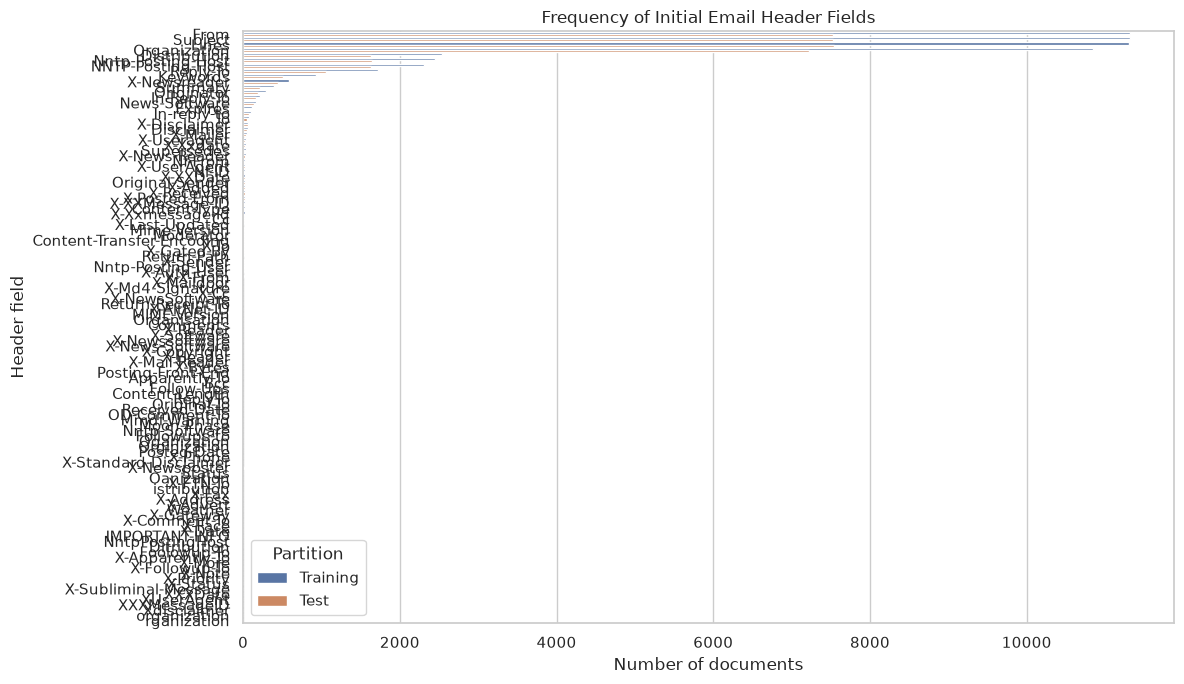

In [41]:
header_plot_data = (
    header_frequency[["Training", "Test"]]
    .reset_index()
    .melt(
        id_vars="header_fields",
        var_name="Partition",
        value_name="Documents",
    )
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=header_plot_data,
    x="Documents",
    y="header_fields",
    hue="Partition",
)

plt.title("Frequency of Initial Email Header Fields")
plt.xlabel("Number of documents")
plt.ylabel("Header field")
plt.legend(title="Partition")
plt.tight_layout()
plt.show()

In [44]:
sample_documents = train_data.sample(
    n=5,
    random_state=RANDOM_SEED,
)

for _, document in sample_documents.iterrows():
    initial_header = document["text"].split(
        "\n\n",
        maxsplit=1,
    )[0]

    print("=" * 80)
    print("Document:", document["document_id"])
    print("Topic:", document["label_name"])
    print("\nInitial header:")
    print(initial_header)

Document: train_007492
Topic: rec.autos

Initial header:
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15
Document: train_003546
Topic: comp.sys.mac.hardware

Initial header:
From: guykuo@carson.u.washington.edu (Guy Kuo)
Subject: SI Clock Poll - Final Call
Summary: Final call for SI clock reports
Keywords: SI,acceleration,clock,upgrade
Article-I.D.: shelley.1qvfo9INNc3s
Organization: University of Washington
Lines: 11
NNTP-Posting-Host: carson.u.washington.edu
Document: train_005582
Topic: comp.sys.mac.hardware

Initial header:
From: twillis@ec.ecn.purdue.edu (Thomas E Willis)
Subject: PB questions...
Organization: Purdue University Engineering Computer Network
Distribution: usa
Lines: 36
Document: train_004793
Topic: comp.graphics

Initial header:
From: jgreen@amber (Joe Green)
Subject: Re: Weitek P9000 ?
Organization: Harris Computer Systems Division
Lines: 14
Dist

In [47]:
# Count each header field at most once per document.
document_header_fields = header_data.copy()

document_header_fields["header_fields"] = (
    document_header_fields["header_fields"].apply(
        lambda fields: sorted({
            field.strip().casefold()
            for field in fields
        })
    )
)

header_frequency = (
    document_header_fields
    .explode("header_fields")
    .dropna(subset=["header_fields"])
    .groupby(["header_fields", "Partition"])["document_id"]
    .nunique()
    .unstack(fill_value=0)
)

header_frequency["Training (%)"] = (
    header_frequency["Training"] / len(train_data) * 100
)

header_frequency["Test (%)"] = (
    header_frequency["Test"] / len(test_data) * 100
)

header_frequency = header_frequency.sort_values(
    "Training",
    ascending=False,
)

display(header_frequency.round(2))

Partition,Test,Training,Training (%),Test (%)
header_fields,,,,
from,7532,11314,100.00,100.00
subject,7532,11314,100.00,100.00
lines,7512,11276,99.66,99.73
organization,7225,10841,95.82,95.92
nntp-posting-host,3268,4764,42.11,43.39
...,...,...,...,...
x-status,1,0,0.00,0.01
xdisclaimer,1,0,0.00,0.01
xuseragent,1,0,0.00,0.01


In [48]:
header_frequency_validation = pd.DataFrame({
    "Partition": ["Training", "Test"],
    "Dataset documents": [
        len(train_data),
        len(test_data),
    ],
    "Documents with From": [
        header_frequency.loc["from", "Training"],
        header_frequency.loc["from", "Test"],
    ],
    "Documents with Subject": [
        header_frequency.loc["subject", "Training"],
        header_frequency.loc["subject", "Test"],
    ],
    "Maximum field frequency": [
        header_frequency["Training"].max(),
        header_frequency["Test"].max(),
    ],
})

display(header_frequency_validation)

,Partition,Dataset documents,Documents with From,Documents with Subject,Maximum field frequency
0,Training,11314,11314,11314,11314
1,Test,7532,7532,7532,7532


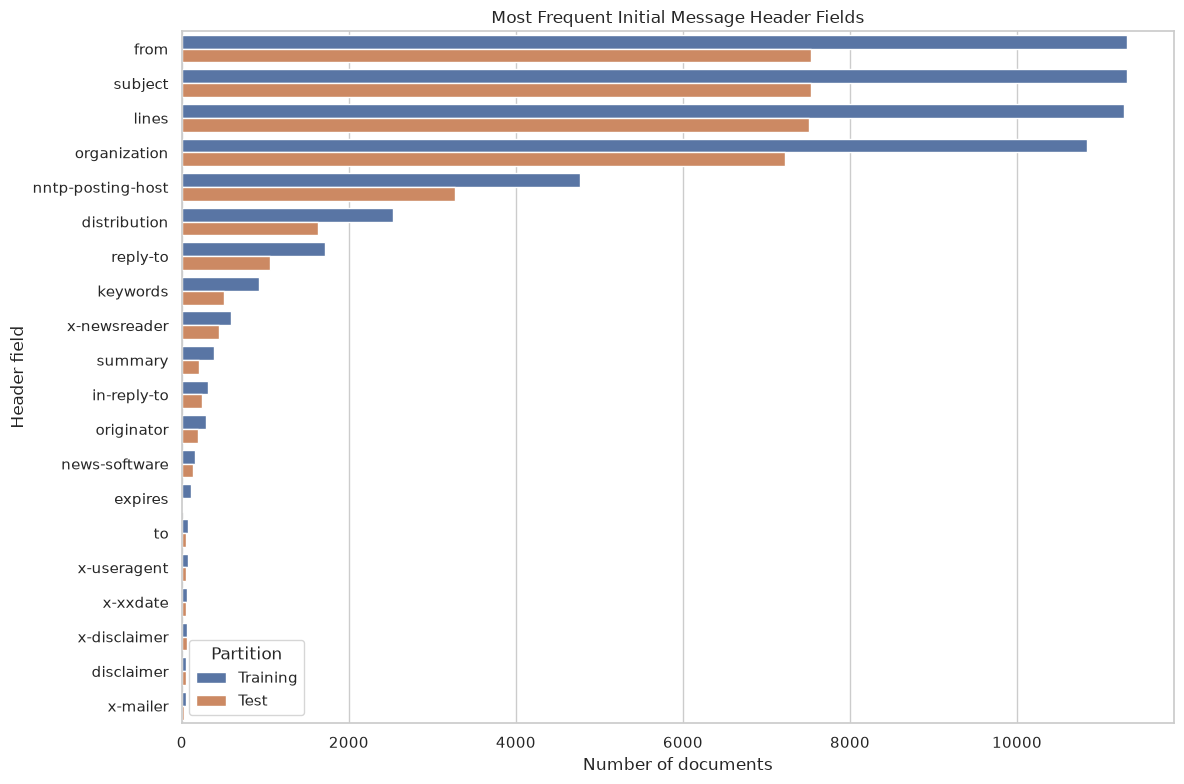

In [49]:
header_plot_data = (
    header_frequency[["Training", "Test"]]
    .head(20)
    .reset_index()
    .melt(
        id_vars="header_fields",
        var_name="Partition",
        value_name="Documents",
    )
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=header_plot_data,
    x="Documents",
    y="header_fields",
    hue="Partition",
)

plt.title("Most Frequent Initial Message Header Fields")
plt.xlabel("Number of documents")
plt.ylabel("Header field")
plt.legend(title="Partition")
plt.tight_layout()
plt.show()


### Interpretation

The initial message headers exhibit a highly consistent structure across the training and test partitions. The `From` and `Subject` fields occur in every document, while `Lines` and `Organization` occur in approximately 99.7% and 95.9% of documents, respectively.

Other fields, including `NNTP-Posting-Host`, occur less frequently. The presence of 112 distinct field names indicates considerable variation in the metadata structure.

Several fields contain information unrelated to the semantic content of the message. Sender identities, organisational affiliations, posting hosts and message identifiers could introduce dataset-specific classification shortcuts.

The `Subject` field requires separate consideration because it may contain legitimate topical information. It will therefore be retained as a potential experimental feature rather than automatically discarded.

The initial header will be separated from the message body during Data Preparation. The original documents will remain unchanged, allowing controlled comparisons between different text representations.

The comparable field frequencies across the training and test partitions suggest that these structural characteristics are present in both official partitions.


In [50]:
def extract_newsgroups_fields(
    text: str,
    target_label: str,
) -> list[dict[str, str | bool]]:
    """Extract Newsgroups fields and identify target-label matches."""

    pattern = re.compile(
        r"^\s*(?P<quotes>(?:>\s*)*)Newsgroups\s*:\s*(?P<value>.*?)\s*$",
        flags=re.IGNORECASE | re.MULTILINE,
    )

    matches = []

    for match in pattern.finditer(text):
        value = match.group("value").strip()

        target_pattern = (
            rf"(?<![\w.-]){re.escape(target_label)}(?![\w.-])"
        )

        matches.append({
            "value": value,
            "quoted": bool(match.group("quotes").strip()),
            "matches_target": bool(
                re.search(target_pattern, value, flags=re.IGNORECASE)
            ),
        })

    return matches


leakage_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        matches = extract_newsgroups_fields(
            text=document["text"],
            target_label=document["label_name"],
        )

        leakage_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "newsgroups_fields": matches,
            "field_count": len(matches),
            "contains_newsgroups": len(matches) > 0,
            "contains_target_match": any(
                item["matches_target"] for item in matches
            ),
            "contains_quoted_newsgroups": any(
                item["quoted"] for item in matches
            ),
            "contains_quoted_target_match": any(
                item["quoted"] and item["matches_target"]
                for item in matches
            ),
        })

leakage_data = pd.DataFrame(leakage_results)

display(
    leakage_data[
        [
            "Partition",
            "document_id",
            "label_name",
            "field_count",
            "contains_newsgroups",
            "contains_target_match",
            "contains_quoted_newsgroups",
            "contains_quoted_target_match",
        ]
    ].head()
)

,Partition,document_id,label_name,field_count,contains_newsgroups,contains_target_match,contains_quoted_newsgroups,contains_quoted_target_match
0,Training,train_000000,rec.sport.baseball,0,False,False,False,False
1,Training,train_000001,comp.sys.mac.hardware,0,False,False,False,False
2,Training,train_000002,sci.crypt,0,False,False,False,False
3,Training,train_000003,comp.sys.mac.hardware,0,False,False,False,False
4,Training,train_000004,alt.atheism,0,False,False,False,False


In [51]:
leakage_summary = (
    leakage_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_Newsgroups=(
            "contains_newsgroups",
            "sum",
        ),
        Documents_with_target_match=(
            "contains_target_match",
            "sum",
        ),
        Documents_with_quoted_Newsgroups=(
            "contains_quoted_newsgroups",
            "sum",
        ),
        Documents_with_quoted_target_match=(
            "contains_quoted_target_match",
            "sum",
        ),
        Total_Newsgroups_fields=("field_count", "sum"),
    )
)

count_columns = [
    "Documents_with_Newsgroups",
    "Documents_with_target_match",
    "Documents_with_quoted_Newsgroups",
    "Documents_with_quoted_target_match",
]

for column in count_columns:
    leakage_summary[f"{column} (%)"] = (
        leakage_summary[column]
        / leakage_summary["Documents"]
        * 100
    )

display(leakage_summary.round(2))

,Documents,Documents_with_Newsgroups,Documents_with_target_match,Documents_with_quoted_Newsgroups,Documents_with_quoted_target_match,Total_Newsgroups_fields,Documents_with_Newsgroups (%),Documents_with_target_match (%),Documents_with_quoted_Newsgroups (%),Documents_with_quoted_target_match (%)
Partition,,,,,,,,,,
Test,7532,48,39,22,20,55,0.64,0.52,0.29,0.27
Training,11314,37,28,14,12,42,0.33,0.25,0.12,0.11


In [52]:
target_match_examples = leakage_data[
    leakage_data["contains_target_match"]
].copy()

print(
    "Documents containing a Newsgroups field matching "
    "their assigned target label:",
    len(target_match_examples),
)

display(
    target_match_examples[
        [
            "Partition",
            "document_id",
            "label_name",
            "newsgroups_fields",
        ]
    ].head(10)
)

Documents containing a Newsgroups field matching their assigned target label: 67


,Partition,document_id,label_name,newsgroups_fields
308,Training,train_000308,misc.forsale,"[{'value': 'rec.audio,misc.forsale', 'quoted': False, 'matches_target': True}]"
1075,Training,train_001075,rec.sport.hockey,"[{'value': 'rec.sport.hockey', 'quoted': True, 'matches_target': True}]"
1506,Training,train_001506,talk.politics.guns,"[{'value': 'talk.politics.guns,ou.politics', 'quoted': True, 'matches_target': True}]"
1671,Training,train_001671,comp.graphics,"[{'value': 'comp.graphics', 'quoted': False, 'matches_target': True}]"
1839,Training,train_001839,talk.politics.misc,"[{'value': 'alt.activism,alt.conspiracy,talk.politics.misc,misc.legal', 'quoted': False, 'matches_target': True}]"
1878,Training,train_001878,comp.windows.x,"[{'value': 'comp.windows.x', 'quoted': True, 'matches_target': True}]"
1912,Training,train_001912,talk.politics.guns,"[{'value': 'talk.politics.guns', 'quoted': True, 'matches_target': True}]"
1934,Training,train_001934,rec.motorcycles,"[{'value': 'rec.motorcycles', 'quoted': False, 'matches_target': True}]"
2149,Training,train_002149,talk.politics.guns,"[{'value': 'talk.politics.guns', 'quoted': False, 'matches_target': True}]"
2307,Training,train_002307,rec.autos,"[{'value': 'rec.autos,rec.autos.vw', 'quoted': False, 'matches_target': True}, {'value': 'rec.autos,rec.autos.vw', '..."


In [55]:
def display_newsgroups_examples(
    leakage_data: pd.DataFrame,
    datasets: dict[str, pd.DataFrame],
    number_of_documents: int = 5,
) -> None:
    """Display matching Newsgroups fields with document context."""

    examples = leakage_data.loc[
        leakage_data["contains_target_match"]
    ].head(number_of_documents)

    # Build document lookups for both original partitions.
    text_lookup = {
        partition: data.set_index("document_id")["text"].to_dict()
        for partition, data in datasets.items()
    }

    for _, document in examples.iterrows():
        partition = document["Partition"]
        document_id = document["document_id"]
        target_label = document["label_name"]

        text = text_lookup[partition][document_id]
        lines = text.splitlines()

        print("=" * 90)
        print("Partition:", partition)
        print("Document:", document_id)
        print("Assigned topic:", target_label)

        target_pattern = (
            rf"(?<![\w.-]){re.escape(target_label)}(?![\w.-])"
        )

        for index, line in enumerate(lines):
            match = re.match(
                r"^\s*(?:>\s*)*Newsgroups\s*:\s*(.*)",
                line,
                flags=re.IGNORECASE,
            )

            if match and re.search(
                target_pattern,
                match.group(1),
                flags=re.IGNORECASE,
            ):
                start = max(0, index - 2)
                end = min(len(lines), index + 3)

                print("\nMatching Newsgroups field:")
                print("Quoted:", bool(re.match(r"^\s*>", line)))

                print("\nContext:")

                for context_line in lines[start:end]:
                    print(context_line)


display_newsgroups_examples(
    leakage_data=leakage_data,
    datasets=datasets,
    number_of_documents=5,
)

Partition: Training
Document: train_000308
Assigned topic: misc.forsale

Matching Newsgroups field:
Quoted: False

Context:


Newsgroups: rec.audio,misc.forsale
Distribution: na
Subject: Forsale: Sony D-22 diskman
Partition: Training
Document: train_001075
Assigned topic: rec.sport.hockey

Matching Newsgroups field:
Quoted: True

Context:

>Post: 51240 of 51243
>Newsgroups: rec.sport.hockey
>From: maynard@ramsey.cs.laurentian.ca (Roger Maynard)
>Subject: Re: Plus minus stat
Partition: Training
Document: train_001506
Assigned topic: talk.politics.guns

Matching Newsgroups field:
Quoted: True

Context:
Here'a a copy, cdt:
------------------------------------------------------------------------
>Newsgroups: talk.politics.guns,ou.politics
>Path: dg-rtp!psinntp!uunet!sun-barr!ames!haven.umd.edu!darwin.sura.net!wupost!csus.edu!netcom.com!mvp
>From: mvp@netcom.com (Mike Van Pelt)
Partition: Training
Document: train_001671
Assigned topic: comp.graphics

Matching Newsgroups field:
Quoted: False


### Interpretation

The investigation identified explicit `Newsgroups:` fields in both official partitions. A subset of these fields contains the same topic identifier as the document's assigned target label.

In total, 67 documents contain a `Newsgroups:` field matching their assigned target: 28 training documents and 39 test documents.

Some matching fields occur in quoted correspondence rather than the initial message header. Consequently, removing only the initial message header would not eliminate all identified instances of this potential leakage.

Although these documents represent a small proportion of the dataset, retaining explicit target identifiers could allow classification models to exploit structural information instead of learning topic-related language patterns.

The findings support inspecting and handling message headers throughout the document during Data Preparation. Quoted correspondence requires separate consideration because it may contain both metadata and legitimate topical information.

The original documents and official labels will remain unchanged. Any removal of structural metadata will be performed in a separate, reproducible preprocessing pipeline.


In [56]:
def find_target_label_occurrences(
    text: str,
    target_label: str,
) -> list[dict[str, str]]:
    """Find occurrences of a document's target label in its text."""

    target_pattern = re.compile(
        rf"(?<![\w.-]){re.escape(target_label)}(?![\w.-])",
        flags=re.IGNORECASE,
    )

    occurrences = []

    for line_number, line in enumerate(text.splitlines(), start=1):
        matches = list(target_pattern.finditer(line))

        if not matches:
            continue

        is_newsgroups = bool(
            re.match(
                r"^\s*(?:>\s*)*Newsgroups\s*:",
                line,
                flags=re.IGNORECASE,
            )
        )

        is_quoted = bool(re.match(r"^\s*>", line))

        if is_newsgroups and is_quoted:
            context_type = "quoted_newsgroups"
        elif is_newsgroups:
            context_type = "unquoted_newsgroups"
        elif is_quoted:
            context_type = "quoted_non_newsgroups"
        else:
            context_type = "unquoted_non_newsgroups"

        for match in matches:
            occurrences.append({
                "line_number": str(line_number),
                "matched_text": match.group(),
                "line": line.strip(),
                "context_type": context_type,
            })

    return occurrences


target_reference_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        occurrences = find_target_label_occurrences(
            text=document["text"],
            target_label=document["label_name"],
        )

        target_reference_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "occurrences": occurrences,
            "occurrence_count": len(occurrences),
            "contains_target_reference": len(occurrences) > 0,
            "contains_non_newsgroups_reference": any(
                item["context_type"] != "unquoted_newsgroups"
                and item["context_type"] != "quoted_newsgroups"
                for item in occurrences
            ),
        })

target_reference_data = pd.DataFrame(target_reference_results)

display(
    target_reference_data[
        [
            "Partition",
            "document_id",
            "label_name",
            "occurrence_count",
            "contains_target_reference",
            "contains_non_newsgroups_reference",
        ]
    ].head()
)

,Partition,document_id,label_name,occurrence_count,contains_target_reference,contains_non_newsgroups_reference
0,Training,train_000000,rec.sport.baseball,0,False,False
1,Training,train_000001,comp.sys.mac.hardware,0,False,False
2,Training,train_000002,sci.crypt,5,True,True
3,Training,train_000003,comp.sys.mac.hardware,0,False,False
4,Training,train_000004,alt.atheism,0,False,False


In [57]:
target_reference_summary = (
    target_reference_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_target_reference=(
            "contains_target_reference",
            "sum",
        ),
        Documents_with_non_newsgroups_reference=(
            "contains_non_newsgroups_reference",
            "sum",
        ),
        Total_target_label_occurrences=(
            "occurrence_count",
            "sum",
        ),
    )
)

for column in [
    "Documents_with_target_reference",
    "Documents_with_non_newsgroups_reference",
]:
    target_reference_summary[f"{column} (%)"] = (
        target_reference_summary[column]
        / target_reference_summary["Documents"]
        * 100
    )

display(target_reference_summary.round(2))

,Documents,Documents_with_target_reference,Documents_with_non_newsgroups_reference,Total_target_label_occurrences,Documents_with_target_reference (%),Documents_with_non_newsgroups_reference (%)
Partition,,,,,,
Test,7532,248,216,307,3.29,2.87
Training,11314,317,291,500,2.80,2.57


In [58]:
context_results = []

for _, document in target_reference_data.iterrows():
    for occurrence in document["occurrences"]:
        context_results.append({
            "Partition": document["Partition"],
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "context_type": occurrence["context_type"],
            "line_number": int(occurrence["line_number"]),
            "line": occurrence["line"],
        })

target_context_data = pd.DataFrame(context_results)

if not target_context_data.empty:
    context_summary = (
        target_context_data
        .groupby(["context_type", "Partition"])
        .agg(
            Occurrences=("line_number", "count"),
            Documents=("document_id", "nunique"),
        )
        .reset_index()
    )

    display(context_summary)
else:
    print("No target-label references were detected.")

,context_type,Partition,Occurrences,Documents
0,quoted_newsgroups,Test,20,20
1,quoted_newsgroups,Training,13,12
2,quoted_non_newsgroups,Test,46,41
3,quoted_non_newsgroups,Training,56,49
4,unquoted_newsgroups,Test,26,19
5,unquoted_newsgroups,Training,20,16
6,unquoted_non_newsgroups,Test,215,176
7,unquoted_non_newsgroups,Training,411,253


In [59]:
non_newsgroups_examples = target_context_data[
    ~target_context_data["context_type"].isin([
        "quoted_newsgroups",
        "unquoted_newsgroups",
    ])
].drop_duplicates(
    subset=["Partition", "document_id", "line_number"]
)

print(
    "Documents with target-label references outside Newsgroups fields:",
    non_newsgroups_examples["document_id"].nunique(),
)

for _, occurrence in non_newsgroups_examples.head(15).iterrows():
    print("=" * 90)
    print("Partition:", occurrence["Partition"])
    print("Document:", occurrence["document_id"])
    print("Assigned topic:", occurrence["label_name"])
    print("Context:", occurrence["context_type"])
    print("Line number:", occurrence["line_number"])
    print("Text:", occurrence["line"])

Documents with target-label references outside Newsgroups fields: 507
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 8
Text: Summary: Part 10 of 10 of the sci.crypt FAQ, References.
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 18
Text: FAQ for sci.crypt, part 10: References
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 20
Text: This is the tenth of ten parts of the sci.crypt FAQ. The parts are
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 27
Text: FAQ is posted to the newsgroups sci.crypt, sci.answers, and news.answers
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 330
Text: There are other newsgroups which a sci.crypt reader might want also to
Par


### Findings: Target-label references throughout documents

Target-label references were identified in 2.80% of training documents and 3.29% of test documents. Most detected occurrences appeared outside explicit `Newsgroups:` fields, including ordinary prose, subject headers, FAQs, and quoted discussions.

Manual inspection demonstrated that these references do not all represent artificial label leakage. For example, references to `sci.crypt` in an FAQ about cryptography or `sci.space` in a discussion about that newsgroup are meaningful parts of the original documents. Other occurrences, particularly those in structural metadata, may provide direct clues about the assigned class.

Consequently, automatically removing every occurrence of a target-label string would be inappropriate. It could remove legitimate topical information and alter the original meaning of documents.

**Data preparation implications:**

- Preserve the original raw documents as an immutable source.
- Investigate and handle structural metadata separately from document content.
- Avoid indiscriminate removal of topic names from ordinary prose.
- Evaluate the effect of metadata and subject information through controlled experiments during modelling.
- Apply identical, reproducible preprocessing rules to training, validation, and test data.

These findings identify potential sources of shortcut learning but do not establish that they cause inflated model performance. Their practical impact must be evaluated empirically.


In [60]:

HEADER_FIELDS_TO_PROFILE = [
    "from",
    "subject",
    "organization",
    "nntp-posting-host",
    "summary",
    "keywords",
    "distribution",
    "newsgroups",
    "message-id",
    "date",
    "path",
    "lines",
    "references",
    "reply-to",
    "sender",
]


def extract_initial_header_values(text: str) -> dict[str, str]:
    """Extract selected values from a document's initial header."""

    header_block = re.split(
        r"\r?\n[ \t]*\r?\n",
        text,
        maxsplit=1,
    )[0]

    parsed_fields = {}
    current_field = None

    for line in header_block.splitlines():
        if line[:1] in (" ", "\t") and current_field is not None:
            parsed_fields[current_field] += " " + line.strip()
            continue

        match = re.match(
            r"^([A-Za-z0-9-]+):\s*(.*)$",
            line,
        )

        if match:
            current_field = match.group(1).casefold()
            value = match.group(2).strip()

            parsed_fields.setdefault(current_field, value)

        else:
            current_field = None

    return {
        field: parsed_fields.get(field, "")
        for field in HEADER_FIELDS_TO_PROFILE
    }


header_records = []

for partition, data in datasets.items():
    for _, document in data.iterrows():
        header_values = extract_initial_header_values(
            document["text"]
        )

        header_records.append({
            "Partition": partition,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            **header_values,
        })

message_headers = pd.DataFrame(header_records)

print("Extracted header records:", len(message_headers))
print("Header fields profiled:", len(HEADER_FIELDS_TO_PROFILE))

display(message_headers.head())

Extracted header records: 18846
Header fields profiled: 15


,Partition,document_id,label_name,from,subject,organization,nntp-posting-host,summary,keywords,distribution,newsgroups,message-id,date,path,lines,references,reply-to,sender
0,Training,train_000000,rec.sport.baseball,cubbie@garnet.berkeley.edu ( ),Re: Cubs behind Marlins? How?,"University of California, Berkeley",garnet.berkeley.edu,,,,,,,,12,,,
1,Training,train_000001,comp.sys.mac.hardware,gnelson@pion.rutgers.edu (Gregory Nelson),Thanks Apple: Free Ethernet on my C610!,"Rutgers Univ., New Brunswick, N.J.",,,,,,,,,26,,,
2,Training,train_000002,sci.crypt,crypt-comments@math.ncsu.edu,Cryptography FAQ 10/10 - References,The Crypt Cabal,pad-thai.aktis.com,"Part 10 of 10 of the sci.crypt FAQ, References. History and classical methods. Modern methods. Survey and reference ...",,,,,,,333,,crypt-comments@math.ncsu.edu,
3,Training,train_000003,comp.sys.mac.hardware,(),Re: Quadra SCSI Problems???,Apple Computer Inc.,,,,,,,,,28,,,
4,Training,train_000004,alt.atheism,keith@cco.caltech.edu (Keith Allan Schneider),Re: <Political Atheists?,"California Institute of Technology, Pasadena",lloyd.caltech.edu,,,,,,,,14,,,


In [61]:

header_completeness = []

for field in HEADER_FIELDS_TO_PROFILE:
    for partition, data in message_headers.groupby("Partition"):
        present = data[field].fillna("").str.strip().ne("")

        header_completeness.append({
            "Header field": field,
            "Partition": partition,
            "Documents": len(data),
            "Documents with value": int(present.sum()),
            "Missing": int((~present).sum()),
            "Present (%)": present.mean() * 100,
        })

header_completeness = pd.DataFrame(header_completeness)

header_completeness_pivot = header_completeness.pivot(
    index="Header field",
    columns="Partition",
    values="Present (%)",
)

header_completeness_pivot.columns.name = None

display(header_completeness_pivot.round(2))

,Test,Training
Header field,,
date,0.00,0.00
distribution,21.57,22.39
from,100.00,100.00
keywords,6.60,8.08
lines,99.67,99.61
message-id,0.00,0.00
newsgroups,0.00,0.00
nntp-posting-host,43.37,42.10
organization,95.90,95.78


In [62]:

header_diversity = []

for field in HEADER_FIELDS_TO_PROFILE:
    for partition, data in message_headers.groupby("Partition"):
        values = (
            data[field]
            .fillna("")
            .str.strip()
        )

        nonempty_values = values[values.ne("")]
        value_counts = nonempty_values.value_counts()

        header_diversity.append({
            "Header field": field,
            "Partition": partition,
            "Documents with value": len(nonempty_values),
            "Distinct values": nonempty_values.nunique(),
            "Distinct value ratio (%)": (
                nonempty_values.nunique()
                / len(nonempty_values)
                * 100
                if len(nonempty_values) > 0
                else 0
            ),
            "Most frequent value (%)": (
                value_counts.iloc[0] / len(nonempty_values) * 100
                if len(nonempty_values) > 0
                else 0
            ),
        })

header_diversity = pd.DataFrame(header_diversity)

display(
    header_diversity
    .sort_values(
        ["Header field", "Partition"]
    )
    .round(2)
)

,Header field,Partition,Documents with value,Distinct values,Distinct value ratio (%),Most frequent value (%)
18,date,Test,0,0,0.00,0.00
19,date,Training,0,0,0.00,0.00
12,distribution,Test,1625,74,4.55,43.51
13,distribution,Training,2533,104,4.11,37.19
0,from,Test,7532,4249,56.41,0.68
1,from,Training,11314,5835,51.57,0.65
10,keywords,Test,497,365,73.44,2.62
11,keywords,Training,914,585,64.00,2.41
22,lines,Test,7507,315,4.20,3.30
23,lines,Training,11270,378,3.35,3.29


In [63]:

FIELDS_FOR_VALUE_INSPECTION = [
    "subject",
    "organization",
    "nntp-posting-host",
    "distribution",
    "summary",
    "keywords",
]

for field in FIELDS_FOR_VALUE_INSPECTION:
    print("\n" + "=" * 90)
    print(f"HEADER FIELD: {field.upper()}")

    for partition, data in message_headers.groupby("Partition"):
        values = (
            data[field]
            .fillna("")
            .str.strip()
        )

        values = values[values.ne("")]

        print(f"\n{partition} — Top 5 values")

        if values.empty:
            print("No values found.")
            continue

        top_values = values.value_counts().head(5)

        for value, count in top_values.items():
            percentage = count / len(values) * 100
            display_value = (
                value[:120] + "..."
                if len(value) > 120
                else value
            )

            print(
                f"{count:>5} ({percentage:>5.2f}%): "
                f"{display_value}"
            )


HEADER FIELD: SUBJECT

Test — Top 5 values
   52 ( 0.69%): Re: Challenge to Microsoft supporters.
   52 ( 0.69%): Re: ATF BURNS DIVIDIAN RANCH! NO SURVIVORS!!!
   51 ( 0.68%): Re: Europe vs. Muslim Bosnians
   50 ( 0.66%): Re: New Study Out On Gay Percentage
   36 ( 0.48%): Re: How to the disks copy protected.

Training — Top 5 values
   76 ( 0.67%): Re: Once tapped, your code is no good any more.
   52 ( 0.46%): Re: Is MSG sensitivity superstition?
   49 ( 0.43%): Re: After 2000 years, can we say that Christian Morality is
   46 ( 0.41%): Re: WARNING.....(please read)...
   43 ( 0.38%): Re: <Political Atheists?

HEADER FIELD: ORGANIZATION

Test — Top 5 values
   84 ( 1.16%): University of Illinois at Urbana
   82 ( 1.14%): AT&T
   53 ( 0.73%): NETCOM On-line Communication Services (408 241-9760 guest)
   50 ( 0.69%): Case Western Reserve University, Cleveland, OH (USA)
   43 ( 0.60%): University of Virginia

Training — Top 5 values
  125 ( 1.15%): University of Illinois at Urbana
   

In [64]:

FIELDS_REQUIRING_VALIDATION = [
    "date",
    "message-id",
    "newsgroups",
    "path",
    "references",
    "sender",
]

for partition, data in datasets.items():
    print("\n" + "=" * 90)
    print(f"PARTITION: {partition}")

    for field in FIELDS_REQUIRING_VALIDATION:
        pattern = re.compile(
            rf"^\s*{re.escape(field)}\s*:",
            flags=re.IGNORECASE,
        )

        matching_examples = []

        for _, document in data.iterrows():
            initial_header = re.split(
                r"\r?\n[ \t]*\r?\n",
                document["text"],
                maxsplit=1,
            )[0]

            matches = [
                line.strip()
                for line in initial_header.splitlines()
                if pattern.match(line)
            ]

            if matches:
                matching_examples.append(
                    (document["document_id"], matches[0])
                )

            if len(matching_examples) >= 3:
                break

        print(f"\n{field.upper()}")

        if matching_examples:
            for document_id, value in matching_examples:
                print(f"{document_id}: {value[:180]}")
        else:
            print("No matching field found in inspected initial headers.")


PARTITION: Training

DATE
No matching field found in inspected initial headers.

MESSAGE-ID
No matching field found in inspected initial headers.

NEWSGROUPS
No matching field found in inspected initial headers.

PATH
No matching field found in inspected initial headers.

REFERENCES
No matching field found in inspected initial headers.

SENDER
No matching field found in inspected initial headers.

PARTITION: Test

DATE
No matching field found in inspected initial headers.

MESSAGE-ID
No matching field found in inspected initial headers.

NEWSGROUPS
No matching field found in inspected initial headers.

PATH
No matching field found in inspected initial headers.

REFERENCES
No matching field found in inspected initial headers.

SENDER
No matching field found in inspected initial headers.


In [66]:
CATEGORICAL_HEADER_FIELDS = [
    "from",
    "subject",
    "organization",
    "nntp-posting-host",
    "summary",
    "keywords",
    "distribution",
    "reply-to",
]

training_headers = message_headers.loc[
    message_headers["Partition"] == "Training"
].copy()

association_results = []

for field in CATEGORICAL_HEADER_FIELDS:
    values = (
        training_headers[field]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    present = values.ne("")
    targets = training_headers["label_name"]

    # Association between field availability and target class.
    presence_ami = adjusted_mutual_info_score(
        targets,
        present.astype(str),
    )

    # Association between actual field values and target class,
    # considering only documents in which the field is present.
    if present.sum() > 1 and values[present].nunique() > 1:
        value_ami = adjusted_mutual_info_score(
            targets[present],
            values[present],
        )
    else:
        value_ami = np.nan

    association_results.append({
        "Header field": field,
        "Documents with value": int(present.sum()),
        "Documents without value": int((~present).sum()),
        "Distinct values": int(values[present].nunique()),
        "Presence AMI": presence_ami,
        "Value AMI (present documents)": value_ami,
    })

header_associations = (
    pd.DataFrame(association_results)
    .sort_values(
        "Value AMI (present documents)",
        ascending=False,
        na_position="last",
    )
    .reset_index(drop=True)
)

display(header_associations.round(4))

,Header field,Documents with value,Documents without value,Distinct values,Presence AMI,Value AMI (present documents)
0,reply-to,1720,9594,793,0.0049,0.3642
1,keywords,914,10400,582,0.0073,0.2742
2,subject,11314,0,6558,0.0000,0.2407
3,nntp-posting-host,4763,6551,1822,0.0183,0.2381
4,from,11314,0,5817,0.0000,0.2379
5,organization,10837,477,2989,0.0079,0.2103
6,distribution,2533,8781,102,0.0146,0.1421
7,summary,391,10923,368,0.0035,0.0546


In [67]:

MIN_VALUE_SUPPORT = 5

FIELDS_FOR_CLASS_ANALYSIS = [
    "reply-to",
    "keywords",
    "subject",
    "nntp-posting-host",
    "from",
    "organization",
    "distribution",
    "summary",
]

header_value_profiles = []

for field in FIELDS_FOR_CLASS_ANALYSIS:
    field_data = training_headers[
        ["document_id", "label_name", field]
    ].copy()

    field_data[field] = (
        field_data[field]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    field_data = field_data[
        field_data[field].ne("")
    ]

    if field_data.empty:
        continue

    value_class_counts = (
        field_data
        .groupby([field, "label_name"])
        .size()
        .unstack(fill_value=0)
    )

    value_totals = value_class_counts.sum(axis=1)

    sufficiently_frequent = value_totals[
        value_totals >= MIN_VALUE_SUPPORT
    ].index

    value_class_counts = value_class_counts.loc[
        sufficiently_frequent
    ]

    for value, class_counts in value_class_counts.iterrows():
        total = int(class_counts.sum())
        dominant_class = class_counts.idxmax()
        dominant_count = int(class_counts.max())

        header_value_profiles.append({
            "Header field": field,
            "Value": value,
            "Documents": total,
            "Dominant class": dominant_class,
            "Dominant class documents": dominant_count,
            "Dominant class share (%)": (
                dominant_count / total * 100
            ),
            "Classes represented": int(
                (class_counts > 0).sum()
            ),
        })

header_value_profiles = pd.DataFrame(
    header_value_profiles
)

print(
    "Header values meeting minimum support:",
    len(header_value_profiles),
)

display(
    header_value_profiles
    .sort_values(
        ["Header field", "Dominant class share (%)", "Documents"],
        ascending=[True, False, False],
    )
    .groupby("Header field", group_keys=False)
    .head(5)
    .round(2)
    .reset_index(drop=True)
)

Header values meeting minimum support: 1596


,Header field,Value,Documents,Dominant class,Dominant class documents,Dominant class share (%),Classes represented
0,distribution,sfnet,5,alt.atheism,5,100.00,1
1,distribution,sci,48,sci.space,46,95.83,2
2,distribution,tx,7,talk.politics.misc,6,85.71,2
3,distribution,rec,21,rec.motorcycles,14,66.67,4
4,distribution,ba,15,misc.forsale,10,66.67,4
5,from,sera@zuma.uucp (serdar argic),70,talk.politics.mideast,70,100.00,1
6,from,keith@cco.caltech.edu (keith allan schneider),52,alt.atheism,52,100.00,1
7,from,cramer@optilink.com (clayton cramer),30,talk.politics.misc,30,100.00,1
8,from,dbd@urartu.sdpa.org (david davidian),29,talk.politics.mideast,29,100.00,1
9,from,jake@bony1.bony.com (jake livni),28,talk.politics.mideast,28,100.00,1


In [68]:

strong_concentrations = header_value_profiles.loc[
    (header_value_profiles["Documents"] >= 10)
    & (
        header_value_profiles["Dominant class share (%)"]
        >= 80
    )
].copy()

strong_concentrations = strong_concentrations.sort_values(
    ["Header field", "Dominant class share (%)", "Documents"],
    ascending=[True, False, False],
)

print(
    "Values with at least 10 documents and 80% class concentration:",
    len(strong_concentrations),
)

display(
    strong_concentrations.round(2).reset_index(drop=True)
)

Values with at least 10 documents and 80% class concentration: 329


,Header field,Value,Documents,Dominant class,Dominant class documents,Dominant class share (%),Classes represented
0,distribution,sci,48,sci.space,46,95.83,2
1,from,sera@zuma.uucp (serdar argic),70,talk.politics.mideast,70,100.00,1
2,from,keith@cco.caltech.edu (keith allan schneider),52,alt.atheism,52,100.00,1
3,from,cramer@optilink.com (clayton cramer),30,talk.politics.misc,30,100.00,1
4,from,dbd@urartu.sdpa.org (david davidian),29,talk.politics.mideast,29,100.00,1
...,...,...,...,...,...,...,...
324,subject,re: what is zero db????,10,sci.electronics,10,100.00,1
325,subject,re: what to do with old 256k simms?,10,sci.electronics,10,100.00,1
326,subject,re: win nt - what is it???,10,comp.os.ms-windows.misc,10,100.00,1
327,subject,re: text of white house announcement and q&as on clipper chip encryption,44,sci.crypt,42,95.45,2


In [69]:

concentration_summary = (
    strong_concentrations
    .groupby("Header field")
    .agg(
        Concentrated_values=("Value", "count"),
        Documents_represented=("Documents", "sum"),
        Mean_class_concentration=(
            "Dominant class share (%)",
            "mean",
        ),
        Maximum_class_concentration=(
            "Dominant class share (%)",
            "max",
        ),
    )
)

field_document_counts = (
    training_headers[ FIELDS_FOR_CLASS_ANALYSIS ]
    .replace(r"^\s*$", np.nan, regex=True)
    .notna()
    .sum()
)

concentration_summary["Documents_with_field"] = (
    field_document_counts
)

concentration_summary["Documents_represented (%)"] = (
    concentration_summary["Documents_represented"]
    / concentration_summary["Documents_with_field"]
    * 100
)

concentration_summary = concentration_summary.sort_values(
    "Documents_represented (%)",
    ascending=False,
)

display(concentration_summary.round(2))

,Concentrated_values,Documents_represented,Mean_class_concentration,Maximum_class_concentration,Documents_with_field,Documents_represented (%)
Header field,,,,,,
reply-to,17,322,97.28,100.00,1720,18.72
subject,107,1861,99.87,100.00,11314,16.45
from,99,1684,95.75,100.00,11314,14.88
nntp-posting-host,33,600,95.43,100.00,4763,12.60
organization,68,1222,93.56,100.00,10837,11.28
keywords,4,62,100.00,100.00,914,6.78
distribution,1,48,95.83,95.83,2533,1.89


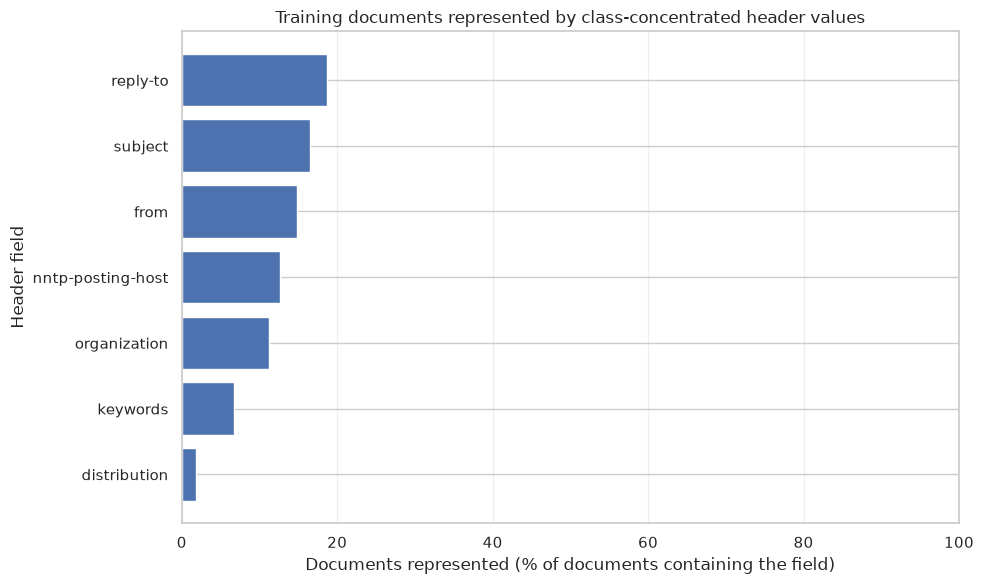

In [70]:

plot_data = concentration_summary.sort_values(
    "Documents_represented (%)",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data.index,
    plot_data["Documents_represented (%)"],
)

ax.set_title(
    "Training documents represented by class-concentrated header values"
)
ax.set_xlabel(
    "Documents represented (% of documents containing the field)"
)
ax.set_ylabel("Header field")

ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Findings: Metadata associations and shortcut-learning risk

The investigation identified substantial associations between several message-header fields and the target classes. Adjusted Mutual Information (AMI) revealed associations between target labels and values in `reply-to` (0.3642), `keywords` (0.2742), `subject` (0.2407), `nntp-posting-host` (0.2381), `from` (0.2379), and `organization` (0.2103).

Further examination identified repeated metadata values strongly concentrated in individual classes. For example, some sender addresses, posting hosts, and organisations appeared exclusively in particular newsgroups. Such patterns could enable shortcut learning, allowing a classifier to associate contributors or infrastructure with target labels rather than learning generalisable topical characteristics.

Subject information presents a different consideration. Although repeated subject lines are strongly associated with particular classes, subjects frequently contain legitimate descriptions of message content. Therefore, their removal should be evaluated experimentally rather than assumed to be necessary.

**Data preparation decisions:**

1. Preserve the original raw documents without modification.
2. Separate initial message headers from message bodies.
3. Exclude author-identifying and infrastructure metadata from the primary modelling representation, including `From`, `Reply-To`, `Organization`, and `NNTP-Posting-Host`.
4. Exclude structural metadata such as `Distribution` and `Lines`.
5. Retain extracted subject information separately for a controlled comparison against a body-only representation.
6. Do not automatically remove topic-name references from ordinary prose.
7. Treat sparse fields such as `Keywords` and `Summary` as supplementary information rather than mandatory model inputs.
8. Evaluate preprocessing decisions using validation data and controlled experiments, reserving the official test partition for final model evaluation.

These decisions establish a content-focused modelling strategy while allowing the contribution of potentially useful subject information to be measured independently.